In [188]:
import os
import random
import string
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd


from PIL import Image, ImageDraw, ImageFont


os.makedirs("original_images", exist_ok=True)
os.makedirs("noisy_images", exist_ok=True)
os.makedirs("filtered_images", exist_ok=True)

In [189]:
os.makedirs("segmented_chars", exist_ok=True)
os.makedirs("resized_chars", exist_ok=True)

In [190]:
LETTER_SPACING = 15  # increase if characters still touch

# Generating strings
chars = string.ascii_lowercase + string.digits
labels = [''.join(random.choices(chars, k=4)) for _ in range(20)]
print(labels)

font = ImageFont.truetype("arialbd.ttf", 40)

W, H = 420, 140

for label in labels:
    img = Image.new("RGB", (W, H), color="white")
    draw = ImageDraw.Draw(img)

    # Measure each character width (so we can add custom spacing)
    char_widths = []
    for ch in label:
        b = draw.textbbox((0, 0), ch, font=font, anchor="ls")
        char_widths.append(b[2] - b[0])

    total_w = sum(char_widths) + LETTER_SPACING * (len(label) - 1)

    # Vertical centering using font metrics (baseline positioning)
    ascent, descent = font.getmetrics()
    text_h = ascent + descent
    x = (W - total_w) // 2
    baseline_y = (H - text_h) // 2 + ascent - 8  # keep your -8 tweak

    # Draw characters with extra spacing
    cur_x = x
    for ch, cw in zip(label, char_widths):
        draw.text((cur_x, baseline_y), ch, fill="black", font=font, anchor="ls")
        cur_x += cw + LETTER_SPACING

    img.save(f"original_images/{label}.png")

print("20 large images saved.")

['tf4u', 'kk73', 'jix9', 'r9t5', 'mlct', 'wfgn', 'j7d3', '1im1', 'a3th', 'tx4b', 'cooa', 'yll3', '74wl', 'qh61', 'znr7', 'w2bc', 's9pi', 'w3z3', '7ynp', 's025']
20 large images saved.


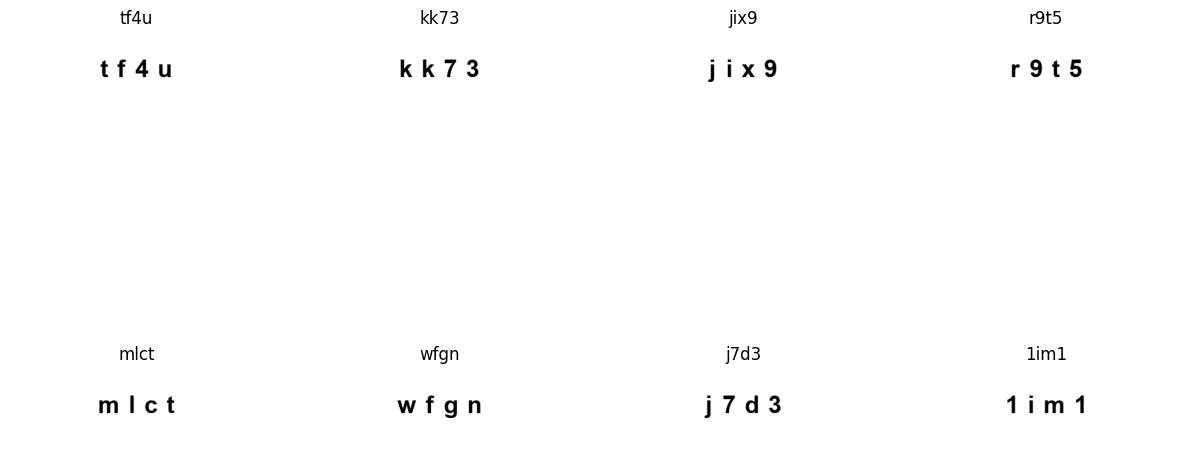

In [191]:
#Displaying the first 8 original images
plt.figure(figsize=(15,8))

for i, label in enumerate(labels[:8]):
    img = Image.open(f'original_images/{label}.png')

    plt.subplot(2,4,i+1)
    plt.imshow(img)
    plt.title(label)
    plt.axis("off")

plt.show()

In [192]:
def add_salt_pepper(image, prob=0.05):

    noisy = np.array(image)

    salt = np.random.random(noisy.shape[:2]) < prob/2
    pepper = np.random.random(noisy.shape[:2]) < prob/2

    noisy[salt] = 255
    noisy[pepper] = 0

    return noisy

for label in labels:

    img = Image.open(f'original_images/{label}.png')

    noisy = add_salt_pepper(img)

    cv2.imwrite(
        f'noisy_images/{label}.png',
        cv2.cvtColor(noisy, cv2.COLOR_RGB2BGR)
    )

print("Noisy images saved.")

Noisy images saved.


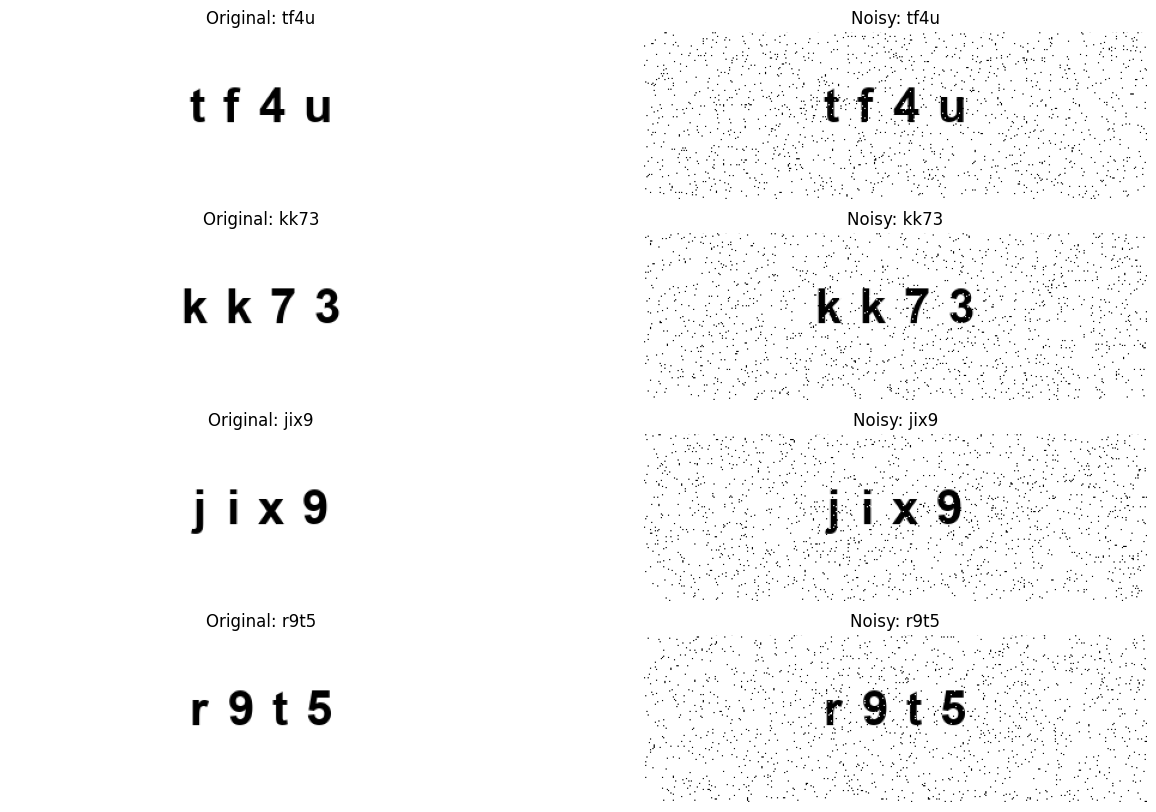

In [193]:
plt.figure(figsize=(15,10))

for i, label in enumerate(labels[:4]):

    orig = Image.open(f'original_images/{label}.png')
    noisy = Image.open(f'noisy_images/{label}.png')

    plt.subplot(4,2,2*i+1)
    plt.imshow(orig)
    plt.title(f"Original: {label}")
    plt.axis("off")

    plt.subplot(4,2,2*i+2)
    plt.imshow(noisy)
    plt.title(f"Noisy: {label}")
    plt.axis("off")

plt.show()

### Why median filtering is good for salt-and-pepper noise? 
Salt-and-pepper noise creates isolated extreme outliers (pixels flipped to 0 or 255). In a small neighborhood (like 3×3), most pixels still belong to the true background/text, so the median ignores those outliers and returns a typical nearby value. Compared to averaging/Gaussian blur, median filtering also preserves edges better (it doesn’t “smear” black/white boundaries as much), which matters for keeping character strokes sharp.

In [194]:
def apply_median_filter(image, ksize=3):
    assert ksize % 2 == 1, "ksize must be odd"
    h, w, c = image.shape
    pad = ksize // 2

    padded = np.pad(
        image,
        ((pad, pad), (pad, pad), (0, 0)),
        mode="reflect"
    )

    output = np.empty_like(image)
    for y in range(h):
        for x in range(w):
            for ch in range(c):
                region = padded[y:y+ksize, x:x+ksize, ch]
                output[y, x, ch] = np.median(region)

    return output.astype(np.uint8)


for label in labels:
    noisy = cv2.imread(f"noisy_images/{label}.png")
    filtered = apply_median_filter(noisy, ksize=3)

    cv2.imwrite(f"filtered_images/{label}.png", filtered)

print("Filtered images saved.")

Filtered images saved.


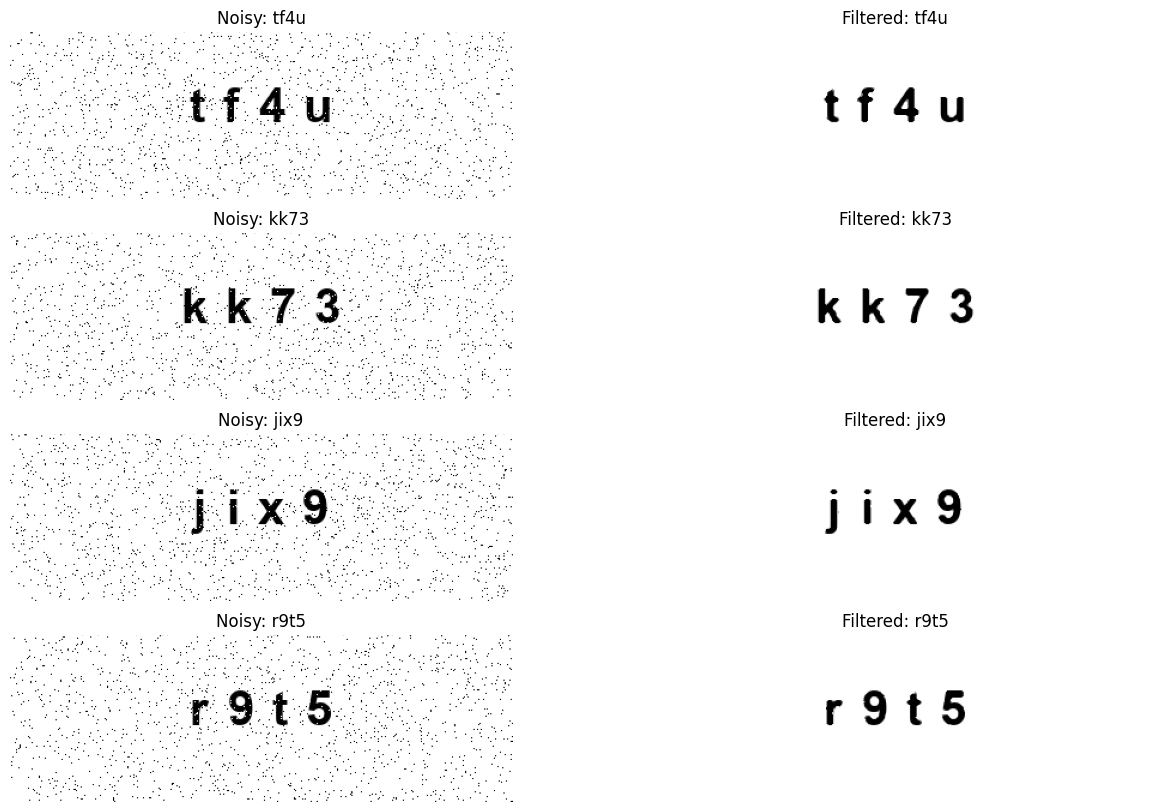

In [195]:
plt.figure(figsize=(15,10))

for i, label in enumerate(labels[:4]):

    noisy = Image.open(f'noisy_images/{label}.png')
    filtered = Image.open(f'filtered_images/{label}.png')

    plt.subplot(4,2,2*i+1)
    plt.imshow(noisy)
    plt.title(f"Noisy: {label}")
    plt.axis("off")

    plt.subplot(4,2,2*i+2)
    plt.imshow(filtered)
    plt.title(f"Filtered: {label}")
    plt.axis("off")

plt.show()

 --- 
 # Part 2

## Step 1: Blur and a different kernel

In [196]:
gaussian_images = {}

for label in labels:

    noisy = cv2.imread(f'noisy_images/{label}.png')

    filtered = cv2.GaussianBlur(
        noisy,
        (7,7),
        1.5
    )

    gaussian_images[label] = filtered

    cv2.imwrite(
        f'filtered_images/gaussian_{label}.png',
        filtered
    )

print("Gaussian filtered images saved.")

Gaussian filtered images saved.


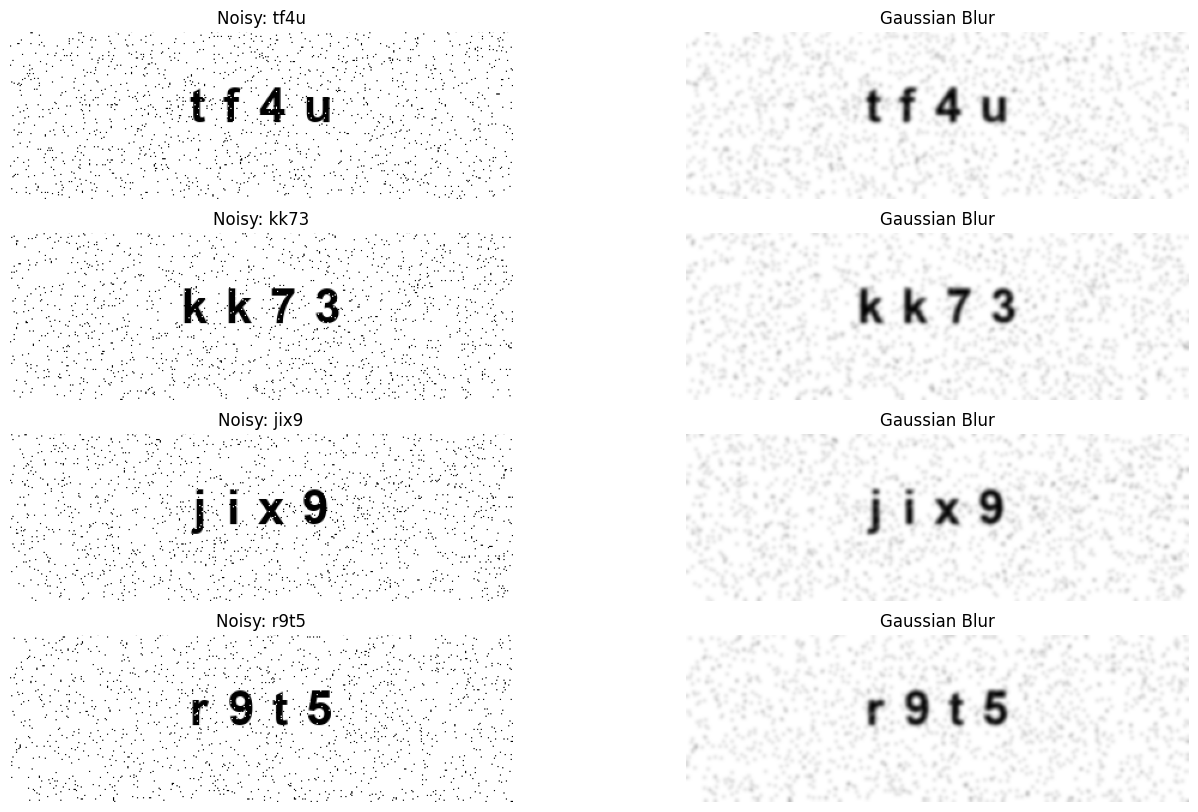

In [197]:
plt.figure(figsize=(16,10))

for i, label in enumerate(labels[:4]):

    noisy = cv2.imread(f'noisy_images/{label}.png')
    noisy = cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB)

    filtered = cv2.cvtColor(
        gaussian_images[label],
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(4,2,2*i+1)
    plt.imshow(noisy)
    plt.title(f"Noisy: {label}")
    plt.axis("off")

    plt.subplot(4,2,2*i+2)
    plt.imshow(filtered)
    plt.title("Gaussian Blur")
    plt.axis("off")

plt.show()

### Why Blur removes noise ?

Blur kernels average neighboring pixels.
Noise usually appears as high-frequency abrupt intensity changes, while real text strokes are larger connected structures.
A blur filter suppresses these sudden local variations by replacing each pixel with a weighted neighborhood average, reducing random noise.
Gaussian blur was chosen because it gives stronger smoothing while preserving overall shape better than simple averaging.

## Step 2: DeBluring and Sharpening

In [198]:
sharpen_kernel = np.array([
    [0,-1,0],
    [-1,5,-1],
    [0,-1,0]
])

sharpened_images = {}

for label in labels:

    blurred = gaussian_images[label]

    sharpened = cv2.filter2D(
        blurred,
        -1,
        sharpen_kernel
    )

    sharpened_images[label] = sharpened

    cv2.imwrite(
        f'filtered_images/sharp_{label}.png',
        sharpened
    )

print("Sharpened images saved.")

Sharpened images saved.


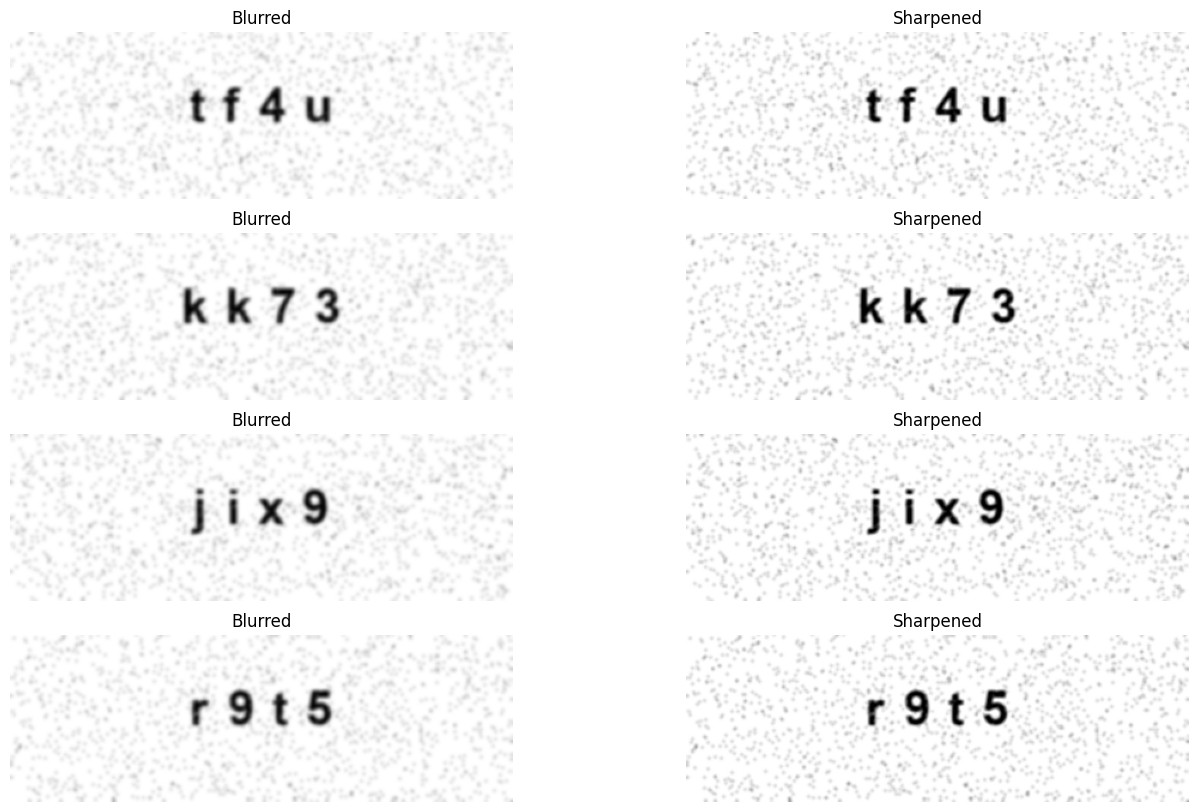

In [199]:
plt.figure(figsize=(16,10))

for i, label in enumerate(labels[:4]):

    before = cv2.cvtColor(
        gaussian_images[label],
        cv2.COLOR_BGR2RGB
    )

    after = cv2.cvtColor(
        sharpened_images[label],
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(4,2,2*i+1)
    plt.imshow(before)
    plt.title("Blurred")
    plt.axis("off")

    plt.subplot(4,2,2*i+2)
    plt.imshow(after)
    plt.title("Sharpened")
    plt.axis("off")

plt.show()

### Sharpening and Deblurring
Sharpening enhances edges by amplifying local intensity differences.
It was chosen because denoising blur reduces high-frequency noise but also softens character boundaries.
Sharpening restores text clarity without reintroducing significant noise.

## Step 3: Binary threshold + remove small connected components

Otsu thresholding is a way to automatically choose a threshold to convert a grayscale image into a binary (black/white) image.

Otsu’s method is a global automatic thresholding technique.
It assumes the grayscale histogram can be roughly split into two groups (classes), typically:

- background pixels
- foreground/text pixels
Otsu searches for the single threshold value *T* that best separates these two classes by minimizing the within-class variance (equivalently maximizing between-class variance). In OpenCV, when we use: 
`_, binary = cv2.threshold(gray_blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)` the 0 threshold you pass is ignored, and OpenCV computes the best global threshold automatically.

In [200]:
def clear_folder(folder):
    for f in os.listdir(folder):
        fp = os.path.join(folder, f)
        if os.path.isfile(fp):
            os.remove(fp)

clear_folder("segmented_chars")
clear_folder("resized_chars")

cleaned_images = {}
AREA_THRESHOLD = 10  # keeping it small for i/j/l

for label in labels:
    # Use sharpened if available (crisper edges)
    if label in sharpened_images:
        img_color = sharpened_images[label]
        gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    else:
        gray = cv2.imread(f"noisy_images/{label}.png", cv2.IMREAD_GRAYSCALE)

    # Otsu + opening only (no close)
    gray_blur = cv2.GaussianBlur(gray, (3, 3), 0)
    _, binary = cv2.threshold(
        gray_blur, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )



    # Connect vertical parts (dot + stem) without merging neighbors horizontally
    vkernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 3))
    #binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, vkernel)

    # Remove speckle noise
    okernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, okernel)

    num_labels, cc, stats, _ = cv2.connectedComponentsWithStats(binary)

    cleaned = np.zeros_like(binary)
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= AREA_THRESHOLD:
            cleaned[cc == i] = 255

    cleaned_images[label] = cleaned
    cv2.imwrite(f"filtered_images/cleaned_{label}.png", cleaned)

print("Connected-component cleaned images saved.")

Connected-component cleaned images saved.


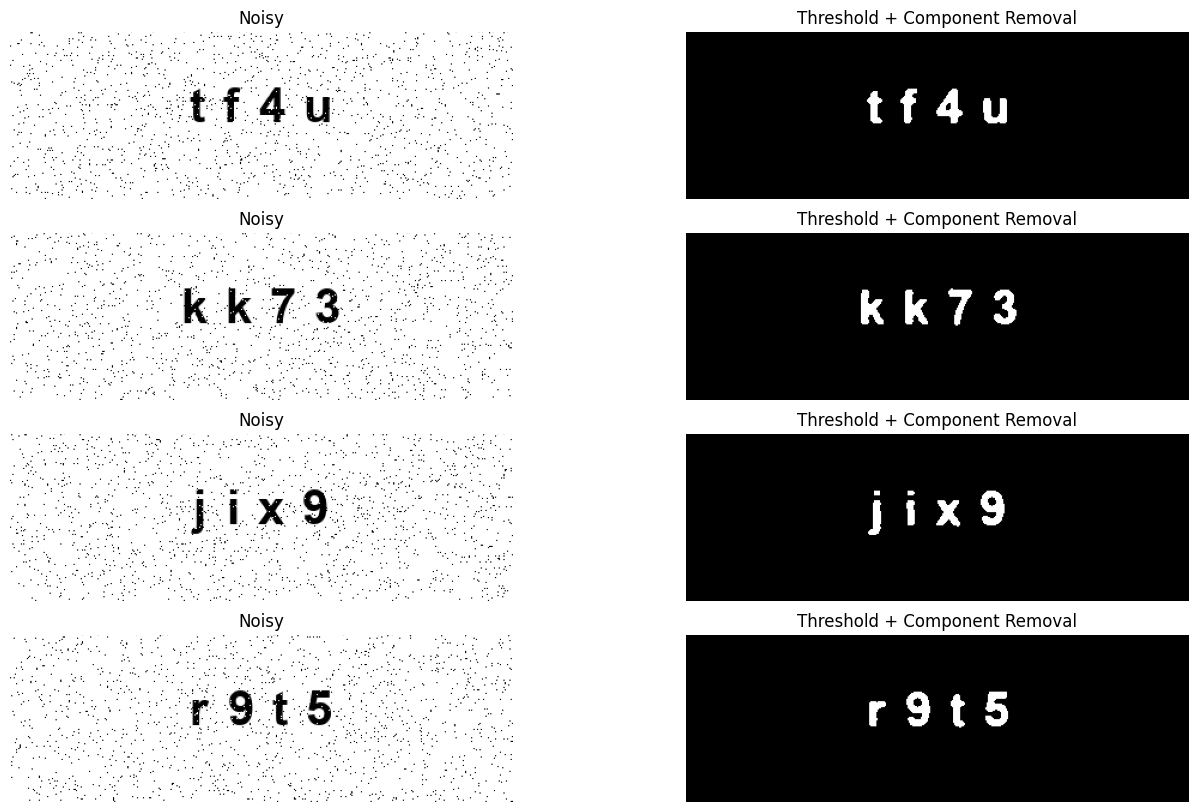

In [201]:
plt.figure(figsize=(16,10))

for i, label in enumerate(labels[:4]):

    noisy = cv2.imread(
        f'noisy_images/{label}.png',
        cv2.IMREAD_GRAYSCALE
    )

    cleaned = cleaned_images[label]

    plt.subplot(4,2,2*i+1)
    plt.imshow(noisy, cmap='gray')
    plt.title("Noisy")
    plt.axis("off")

    plt.subplot(4,2,2*i+2)
    plt.imshow(cleaned, cmap='gray')
    plt.title("Threshold + Component Removal")
    plt.axis("off")

plt.show()

### Explanation of Threshold and what it depends on :

Threshold is the intensity cutoff used to convert grayscale into binary:

- pixels above threshold → white
- pixels below threshold → black

It separates foreground (text) from background.

IT is not fixed and depends on:

- font thickness
- contrast
- image quality
- noise level

Different datasets require different thresholds, Adaptive thresholding can compute it automatically.
connected-component removal works because Salt-and-pepper noise produces tiny isolated blobs while characters form larger connected regions, Removing connected components smaller than a chosen area threshold eliminates noise while preserving text.

 --- 
 # Part 3

## Step 1: Segmenting all of the strings

### Basic connected componetnts segmentation:

This cell takes each cleaned binary image (from cleaned_images[label]) and extracts characters by treating each connected white blob as a candidate character.

- Input: img = cleaned_images[label] where text is foreground (typically 255) and background is 0.
Find components: cv2.connectedComponentsWithStats(img) labels each connected foreground region and returns stats (bounding box + area) for each region.
- Remove small blobs: it keeps only components with area > 80. This removes leftover speckles and tiny noise that survived thresholding.
- Crop each component:
  - Reads the component bounding box (x, y, w, h) from stats
  - Extracts char = img[y:y+h, x:x+w]
- Sort left-to-right: it stores (x, char) and then sorts by x so the characters are in reading order.
- Save results: writes each crop as segmented_chars/{label}_{idx}.png and counts how many were extracted.

Works well when each character becomes a separate connected component.


In [202]:
character_counts = {}

for label in labels:

    img = cleaned_images[label]

    num_labels, cc, stats, _ = cv2.connectedComponentsWithStats(img)

    chars = []

    for i in range(1, num_labels):

        area = stats[i, cv2.CC_STAT_AREA]

        if area > 80:

            x = stats[i, cv2.CC_STAT_LEFT]
            y = stats[i, cv2.CC_STAT_TOP]
            w = stats[i, cv2.CC_STAT_WIDTH]
            h = stats[i, cv2.CC_STAT_HEIGHT]

            char = img[y:y+h, x:x+w]

            chars.append((x, char))

    # Sort left-to-right
    chars.sort(key=lambda item: item[0])

    extracted = []

    for idx, (_, char) in enumerate(chars):

        filename = f"{label}_{idx}.png"

        cv2.imwrite(
            f"segmented_chars/{filename}",
            char
        )

        extracted.append(char)

    character_counts[label] = len(extracted)

    print(
        f"{label}: {len(extracted)} characters extracted"
    )

tf4u: 4 characters extracted
kk73: 4 characters extracted
jix9: 4 characters extracted
r9t5: 4 characters extracted
mlct: 4 characters extracted
wfgn: 4 characters extracted
j7d3: 4 characters extracted
1im1: 4 characters extracted
a3th: 4 characters extracted
tx4b: 4 characters extracted
cooa: 4 characters extracted
yll3: 4 characters extracted
74wl: 4 characters extracted
qh61: 4 characters extracted
znr7: 4 characters extracted
w2bc: 4 characters extracted
s9pi: 4 characters extracted
w3z3: 4 characters extracted
7ynp: 4 characters extracted
s025: 4 characters extracted


### Improved segmentation

since I had an issue with segmentation, for example in i, j the dot was missed from the segmentation because the previous cell focused on the connected components. I added some enhancements to the segmentation algorithm.

it works as follows : 

1. Extract initial component boxes

- It runs connectedComponentsWithStats again but keeps even smaller parts (drops only very tiny speckle with area < 8).
- It stores each component as a dict: `{"x","y","w","h","area"}` (a bounding box + area).
2.  `merge_dots()` — attach dot components to stems
- Splits components into:
- “big” components (likely real letters)
- “dots” (small components, likely the dot of i/j)
- For each dot, it searches for a big component below it with horizontal overlap and a small vertical gap (max_gap_y).
- If found, it unions the bounding boxes (so dot+stem becomes one character box).
- Result: reduces the “extra component” problem for dotted letters.

Key idea: the dot is usually above its stem and roughly aligned in x, so merging by overlap + vertical distance is a good heuristic.

3. `split_box_by_projection()` — split characters that got stuck together *(This is not used, it was needed because the letter distance was so low and the characters appeared scuffed, since I was unable to get a good accuracy that way, I increased the letter distance in the image generation part).*
- If you end up with fewer than 4 boxes, that often means some letters touched and became one wide component.
- For a wide box, it computes a vertical projection: how many foreground pixels exist in each column.
- It finds a valley (minimum) in that projection and cuts there → producing two boxes.
- It repeats splitting the widest box until it reaches 4 boxes (or can’t split anymore).

Key idea: between two touching letters there’s often a thin vertical gap, which shows up as a dip in the column-sum projection.


4. Final extraction + tighter cropping
- After merging/splitting, it sorts boxes by x and extracts up to 4 crops.
- Then it tight-crops each crop to actual foreground pixels using np.where(char > 0) and a tiny margin = 1.
- Saves the final crops to segmented_chars/{label}_{idx}.png.

In [203]:
def merge_dots(boxes, dot_max_area=40, max_gap_y=15):
    # boxes: list of dicts with x,y,w,h,area
    big = [b for b in boxes if b["area"] >= dot_max_area]
    dots = [b for b in boxes if b["area"] < dot_max_area]

    for d in dots:
        dx0, dx1 = d["x"], d["x"] + d["w"]
        dy_bottom = d["y"] + d["h"]

        # find a big component under the dot with x-overlap
        best = None
        best_overlap = 0
        for b in big:
            bx0, bx1 = b["x"], b["x"] + b["w"]
            by_top = b["y"]

            overlap = max(0, min(dx1, bx1) - max(dx0, bx0))
            if overlap <= 0:
                continue
            if not (by_top >= dy_bottom and (by_top - dy_bottom) <= max_gap_y):
                continue

            if overlap > best_overlap:
                best_overlap = overlap
                best = b

        if best is not None:
            # union bbox
            x0 = min(best["x"], d["x"])
            y0 = min(best["y"], d["y"])
            x1 = max(best["x"] + best["w"], d["x"] + d["w"])
            y1 = max(best["y"] + best["h"], d["y"] + d["h"])
            best.update({"x": x0, "y": y0, "w": x1 - x0, "h": y1 - y0, "area": best["area"] + d["area"]})

    return big  # dots merged into big where possible


def split_box_by_projection(img, box):
    # Splits one box into two using a valley in vertical projection
    x, y, w, h = box["x"], box["y"], box["w"], box["h"]
    roi = img[y:y+h, x:x+w]
    proj = (roi > 0).sum(axis=0)  # foreground count per column

    # avoid cutting too close to edges
    left = max(2, w // 6)
    right = min(w - 3, w - w // 6)
    if right <= left:
        return [box]

    cut = left + int(np.argmin(proj[left:right]))

    b1 = {"x": x, "y": y, "w": cut, "h": h, "area": int((roi[:, :cut] > 0).sum())}
    b2 = {"x": x + cut, "y": y, "w": w - cut, "h": h, "area": int((roi[:, cut:] > 0).sum())}
    return [b1, b2]


character_counts = {}

for label in labels:
    img = cleaned_images[label]  # binary with text=255

    num_labels, cc, stats, _ = cv2.connectedComponentsWithStats(img)

    boxes = []
    for i in range(1, num_labels):
        x = int(stats[i, cv2.CC_STAT_LEFT])
        y = int(stats[i, cv2.CC_STAT_TOP])
        w = int(stats[i, cv2.CC_STAT_WIDTH])
        h = int(stats[i, cv2.CC_STAT_HEIGHT])
        area = int(stats[i, cv2.CC_STAT_AREA])

        # keep small-ish parts too (dots), but drop true speckle
        if area < 8:
            continue
        boxes.append({"x": x, "y": y, "w": w, "h": h, "area": area})

    # merge dot-like components into stems (fixes j/i)
    boxes = merge_dots(boxes, dot_max_area=40, max_gap_y=20)

    # If we have fewer than 4 components, split the widest boxes until we reach 4
    boxes.sort(key=lambda b: b["w"], reverse=True)
    while len(boxes) < 4 and len(boxes) > 0:
        widest = boxes.pop(0)
        split = split_box_by_projection(img, widest)
        if len(split) == 1:
            boxes.append(widest)
            break
        boxes.extend(split)
        boxes.sort(key=lambda b: b["w"], reverse=True)

    # Now sort left-to-right and extract
    boxes.sort(key=lambda b: b["x"])

    extracted = []
    for idx, b in enumerate(boxes[:4]):  # enforce 4 chars
        # NO padding around the component bbox
        x0 = max(0, b["x"])
        y0 = max(0, b["y"])
        x1 = min(img.shape[1], b["x"] + b["w"])
        y1 = min(img.shape[0], b["y"] + b["h"])

        char = img[y0:y1, x0:x1]

        # Tight-crop to foreground, with a *tiny* margin (keeps it clean, not centered)
        ys, xs = np.where(char > 0)
        if ys.size > 0:
            margin = 1  # set to 0 if you want absolutely no edge
            y_min = max(0, ys.min() - margin)
            y_max = min(char.shape[0] - 1, ys.max() + margin)
            x_min = max(0, xs.min() - margin)
            x_max = min(char.shape[1] - 1, xs.max() + margin)
            char = char[y_min:y_max + 1, x_min:x_max + 1]

        filename = f"{label}_{idx}.png"
        cv2.imwrite(f"segmented_chars/{filename}", char)
        extracted.append(char)

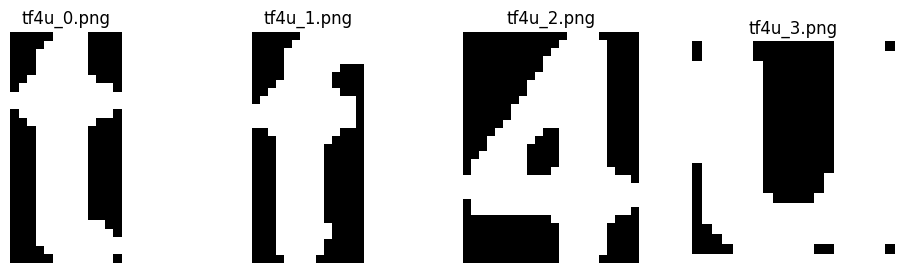

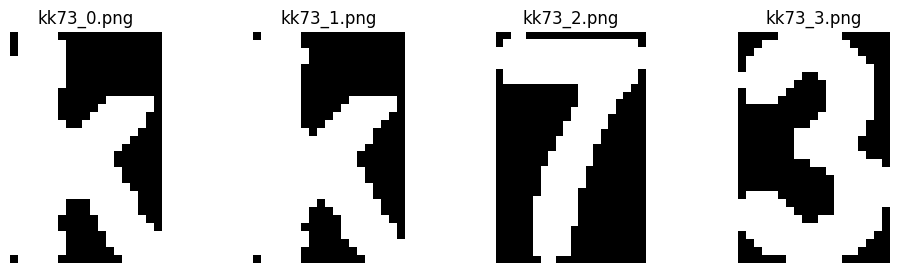

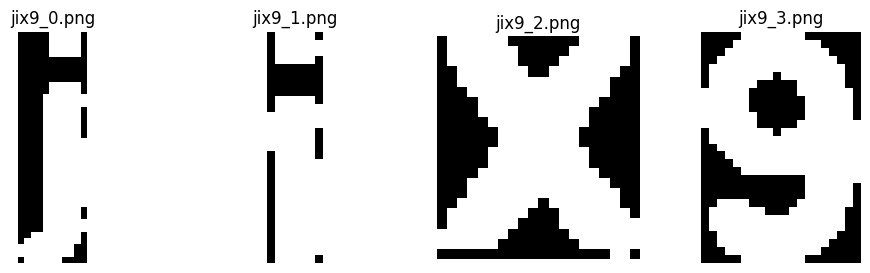

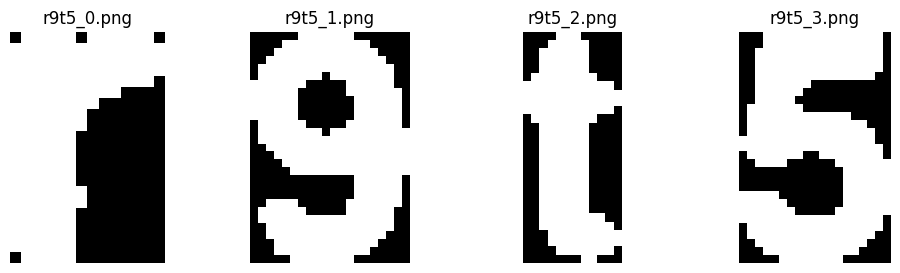

In [204]:
for label in labels[:4]:

    files = sorted([
        f for f in os.listdir("segmented_chars")
        if f.startswith(label)
    ])

    plt.figure(figsize=(12,3))

    for i, file in enumerate(files):

        img = cv2.imread(
            f"segmented_chars/{file}",
            cv2.IMREAD_GRAYSCALE
        )

        plt.subplot(1, len(files), i+1)
        plt.imshow(img, cmap='gray')
        plt.title(file)
        plt.axis("off")

    plt.show()

## Step 2: Resizing all segmented characters to 64×64

function, center_resize is using the same cv2 resize function but centers the character before resizing, so the edges are still in the picture and the shape of the character is more obvious and distinguishable. (After trying this, even though the characters looked better but because the mapset itself is not centered, it just reduced the accuracy by 50%, so it's not useful here).

In [205]:
# # def center_resize(img, size=64):

# #     h, w = img.shape

# #     scale = min((size-8)/w, (size-8)/h)

# #     nw = int(w*scale)
# #     nh = int(h*scale)

# #     resized = cv2.resize(
# #         img,
# #         (nw, nh),
# #         interpolation=cv2.INTER_NEAREST
# #     )

# #     canvas = np.zeros((size,size), dtype=np.uint8)

# #     x = (size-nw)//2
# #     y = (size-nh)//2

# #     canvas[y:y+nh, x:x+nw] = resized

# #     return canvas

# for filename in os.listdir("segmented_chars"):

#     image_path = os.path.join(
#         "segmented_chars",
#         filename
#     )

#     character = cv2.imread(
#         image_path,
#         cv2.IMREAD_GRAYSCALE
#     )

#     resized = cv2.resize(
#         character,
#         (64, 64),
#         interpolation=cv2.INTER_NEAREST
#     )

#     _, resized = cv2.threshold(
#         resized,
#         127,
#         255,
#         cv2.THRESH_BINARY
#     )

#     cv2.imwrite(
#         os.path.join(
#             "resized_chars",
#             filename
#         ),
#         resized
#     )

# print("Characters resized correctly.")
for filename in os.listdir("segmented_chars"):

    image_path = os.path.join("segmented_chars", filename)

    character = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    # Direct resize to 64x64 (preserves position like mapset)
    resized = cv2.resize(character, (64, 64), interpolation=cv2.INTER_NEAREST)

    # Threshold after resize
    _, resized = cv2.threshold(resized, 127, 255, cv2.THRESH_BINARY)

    cv2.imwrite(
        os.path.join("resized_chars", filename),
        resized
    )

print("Characters resized correctly.")


Characters resized correctly.


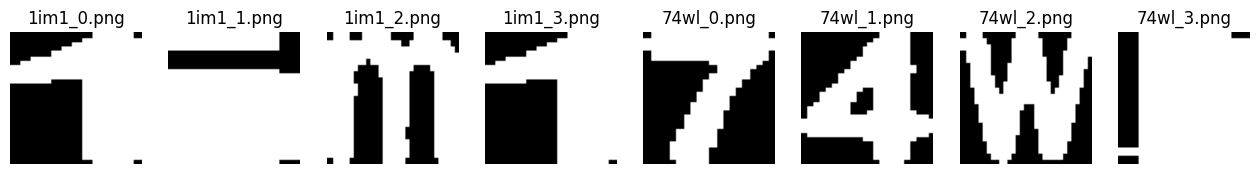

In [206]:
files = os.listdir("resized_chars")[:8]

plt.figure(figsize=(16,4))

for i, file in enumerate(files):

    img = cv2.imread(
        f"resized_chars/{file}",
        cv2.IMREAD_GRAYSCALE
    )

    plt.subplot(1,8,i+1)
    plt.imshow(img, cmap='gray')
    plt.title(file)
    plt.axis("off")

plt.show()

 ---
 # Part 4

## Step 1: Load mapset templates, finding similarities, and CSV output

In [207]:
# Loading Mapset
MAPSET_PATH = r'D:\UT\Vision\CA2\Description\Mapset\Mapset'

templates = {}

for file in os.listdir(MAPSET_PATH):

    if file.endswith('.png'):

        label = file.split('.')[0]

        img = cv2.imread(
            os.path.join(MAPSET_PATH, file),
            cv2.IMREAD_GRAYSCALE
        )

        img = cv2.resize(
            img,
            (64,64),
            interpolation=cv2.INTER_NEAREST
        )

        _, img = cv2.threshold(
            img,
            127,
            255,
            cv2.THRESH_BINARY
        )

        templates[label] = img

print(f"{len(templates)} templates loaded")

36 templates loaded


### The similarity function : 
Cross-correlation measures similarity by multiplying corresponding pixels and summing the result. High values indicate strong structural agreement between the segmented character and reference template. Unlike convolution, cross-correlation does not flip the template. Since OCR requires direct structural comparison rather than mirrored matching, normalized cross-correlation was preferred and produced more accurate recognition results.

In [208]:
def corr_similarity(img, template):

    img = img.astype(np.float32)
    template = template.astype(np.float32)

    img -= np.mean(img)
    template -= np.mean(template)

    numerator = np.sum(img * template)

    denominator = np.sqrt(
        np.sum(img**2) *
        np.sum(template**2)
    )

    if denominator == 0:
        return 0

    return numerator / denominator

### normalized cross-correlation and MSE (UNUSED)

In [209]:
# Normalized Cross-Correlation
# def similarity(img1, img2):

#     img1 = img1.astype(np.float32)
#     img2 = img2.astype(np.float32)

#     img1 -= np.mean(img1)
#     img2 -= np.mean(img2)

#     numerator = np.sum(img1 * img2)

#     denominator = np.sqrt(
#         np.sum(img1**2) *
#         np.sum(img2**2)
#     )

#     if denominator == 0:
#         return 0

#     return numerator / denominator

# MSE
# def similarity(img1, img2):

#     mse = np.mean(
#         (img1.astype(np.float32) -
#          img2.astype(np.float32)) ** 2
#     )

#     return -mse

### Prediction : 

For each resized character, compares against all templates using `corr_similarity()` and picks the best-scoring label; stores results. Used to perform the actual template-matching OCR.

In [210]:
results = []

for file in os.listdir("resized_chars"):
    img = cv2.imread(os.path.join("resized_chars", file), cv2.IMREAD_GRAYSCALE)
    _, img = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

    best_label = None
    best_score = -1  # internal only

    for label, template in templates.items():
        score = corr_similarity(img, template)
        if score > best_score:
            best_score = score
            best_label = label

    results.append({
        "segment file": file,
        "predicted label": best_label
    })

print("Prediction complete")

Prediction complete


### Accuracy calculation

Parses ground-truth from filenames, builds an evaluation table, and computes character accuracy and full-string accuracy. Used to quantify performance at both per-character and “all 4 correct” levels.

In [211]:
def parse_truth_from_filename(fname):
    stem = os.path.splitext(fname)[0]    # e.g. "54o4_2"
    base, idx_str = stem.rsplit("_", 1)  # base="54o4", idx_str="2"
    idx = int(idx_str)
    truth = base[idx] if 0 <= idx < len(base) else None
    return base, idx, truth

eval_rows = []
for r in results:
    seg = r["segment file"]
    base, pos, truth = parse_truth_from_filename(seg)
    pred = r["predicted label"]
    eval_rows.append({"segment file": seg, "base": base, "pos": pos, "truth": truth, "pred": pred})

df_eval = pd.DataFrame(eval_rows)
df_eval["correct"] = (df_eval["truth"] == df_eval["pred"])

char_acc = df_eval["correct"].mean()
string_acc = df_eval.groupby("base")["correct"].all().mean()

print(f"Character accuracy: {char_acc:.3%}  ({df_eval['correct'].sum()}/{len(df_eval)})")
print(f"String accuracy:    {string_acc:.3%}  ({df_eval.groupby('base')['correct'].all().sum()}/{df_eval['base'].nunique()})")

Character accuracy: 90.000%  (72/80)
String accuracy:    70.000%  (14/20)


### About the Accuracy: 

problems with accuracy here is that in each run, there is a value between 82-94 depending on the characters generated. The main problem in my code is for characters like : c, 0 , o , g , q. it was for i, j , l , 1 bit it was fixed with the improvement of segmentaion. 
despite tryinng many options. for example a function that calculates if there is actually a circle or there exists a space between them (for distinguishing between c and o,0 ), i was not able to handle this problem. therefore the accuracy varies between 82-94 in all of my tests.

### Saving into csv
Writes a CSV with per-segment truth/prediction and a 0/1 accuracy column.

In [212]:
df_out = df_eval.copy()
df_out["accuracy"] = df_out["correct"].astype(int)

df_out = df_out[[
    "segment file",
    "truth",
    "pred",
    "accuracy",
]]

df_out.to_csv("prediction_results.csv", index=False)
print("CSV saved (accuracy exported, metric removed).")

CSV saved (accuracy exported, metric removed).


In [213]:
pd.read_csv("prediction_results.csv").head(20)

,segment file,truth,pred,accuracy
0,1im1_0.png,1,1,1
1,1im1_1.png,i,i,1
2,1im1_2.png,m,m,1
3,1im1_3.png,1,1,1
4,74wl_0.png,7,7,1
5,74wl_1.png,4,4,1
6,74wl_2.png,w,w,1
7,74wl_3.png,l,j,0
8,7ynp_0.png,7,7,1
9,7ynp_1.png,y,y,1


In [214]:
grouped = {}

for row in results:

    base = "_".join(row["segment file"].split("_")[:-1])

    if base not in grouped:
        grouped[base] = []

    idx = int(
        row["segment file"]
        .split("_")[-1]
        .split(".")[0]
    )

    grouped[base].append(
        (idx, row["predicted label"])
    )

for name, chars in grouped.items():

    chars.sort()

    pred = ''.join([c for _, c in chars])

    print(f"{name} -> {pred}")

1im1 -> 1im1
74wl -> 74wj
7ynp -> 7ynp
a3th -> a3th
cooa -> c00a
j7d3 -> j7d3
jix9 -> jix9
kk73 -> kk73
mlct -> mtct
qh61 -> qh61
r9t5 -> r9t5
s025 -> so25
s9pi -> s9pi
tf4u -> tf4u
tx4b -> tx4b
w2bc -> w2bc
w3z3 -> w3z3
wfgn -> wfqn
yll3 -> yij3
znr7 -> znr7
